Language: **English (default)** | [Polski](lab.ipynb)

# Lab 07 -- adapting a pretrained model (EuroSAT)

Companion material to [`README.md`](README.md). A different dataset than
the lecture (EuroSAT, satellite imagery, not Caltech101) and a different
question: does transfer learning from ImageNet help when the domain is
visually distant, and does partial fine-tuning give anything here beyond
a frozen backbone alone.

In [1]:
import contextlib
import io

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torchvision.datasets as tvd
from torchvision.models import ResNet18_Weights, resnet18  # noqa: F401 - used in the TODO below

torch.manual_seed(0)
torch.set_num_threads(4)  # BLAS thread stability under jupyter/ipykernel
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


## 1. Data: EuroSAT -- structure and exploration

number of images: 27000, number of classes: 10
classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


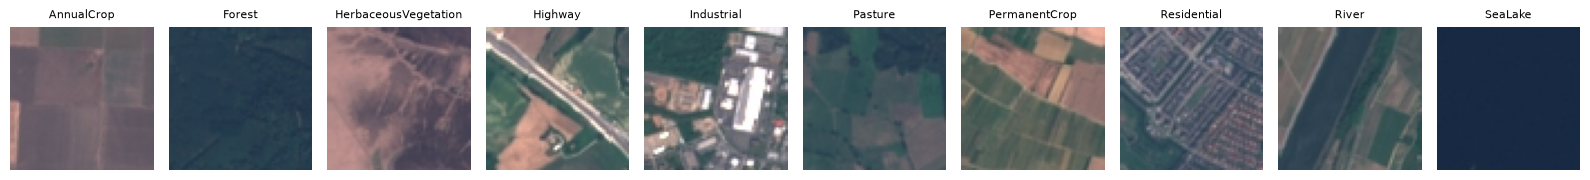

In [2]:
with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
    full_ds = tvd.EuroSAT(root="data_cache", download=True)

CLASSES = full_ds.classes
print(f"number of images: {len(full_ds)}, number of classes: {len(CLASSES)}")
print("classes:", CLASSES)

fig, axes = plt.subplots(1, 10, figsize=(16, 2))
shown = set()
for img, label in full_ds:
    if label not in shown:
        axes[label].imshow(img)
        axes[label].set_title(CLASSES[label], fontsize=8)
        axes[label].axis("off")
        shown.add(label)
    if len(shown) == 10:
        break
plt.tight_layout()
plt.show()

**Task:** do these images resemble anything from ImageNet (animals,
objects, "ground-level" scenes)? Write down, in a sentence, your initial
intuition about whether transfer learning from ImageNet should help
here.

_(Your answer here.)_

## 2. Preprocessing consistent with the pretrained weights

ResNet18 requires **exactly** the preprocessing used during training on
ImageNet -- otherwise the features learned by the backbone will not make
sense for the new data.

In [3]:
def build_preprocess():
    # TODO: return a transform CONSISTENT with the ResNet18_Weights.IMAGENET1K_V1
    # weights (hint: the weights object has a ready-made .transforms()
    # method -- use it, do not rewrite the size/normalization by hand)
    raise NotImplementedError("TODO: build_preprocess")


preprocess = build_preprocess()
print(preprocess)

NotImplementedError: TODO: build_preprocess

In [4]:
sample_img, _ = full_ds[0]
sample_tensor = preprocess(sample_img)
print(f"shape after preprocessing: {tuple(sample_tensor.shape)}")
assert sample_tensor.shape == (3, 224, 224), "expected (3, 224, 224)"
print("OK: preprocessing consistent with ResNet18's input.")

NameError: name 'preprocess' is not defined

## 3. Train/val/test split (provided)

50 images/class (500 total), split 30/10/10 into train/val/test.

In [5]:
PER_CLASS = 50
class_to_indices = {c: [] for c in range(10)}
for idx, (_, label) in enumerate(full_ds):
    if len(class_to_indices[label]) < PER_CLASS:
        class_to_indices[label].append(idx)
    if all(len(v) >= PER_CLASS for v in class_to_indices.values()):
        break

selected_indices = [idx for c in range(10) for idx in class_to_indices[c]]
selected_labels = [c for c in range(10) for _ in class_to_indices[c]]

imgs = [preprocess(full_ds[idx][0]) for idx in selected_indices]
X = torch.stack(imgs)
y = torch.tensor(selected_labels)
print(f"X={tuple(X.shape)}  y={tuple(y.shape)}")

g = torch.Generator().manual_seed(0)
train_idx, val_idx, test_idx = [], [], []
for c in range(10):
    positions = (y == c).nonzero().flatten()
    perm = positions[torch.randperm(len(positions), generator=g)]
    train_idx.append(perm[:30])
    val_idx.append(perm[30:40])
    test_idx.append(perm[40:50])
train_idx, val_idx, test_idx = torch.cat(train_idx), torch.cat(val_idx), torch.cat(test_idx)
assert len(set(train_idx.tolist()) & set(val_idx.tolist()) & set(test_idx.tolist())) == 0

X_train, y_train = X[train_idx].to(device), y[train_idx].to(device)
X_val, y_val = X[val_idx].to(device), y[val_idx].to(device)
X_test, y_test = X[test_idx].to(device), y[test_idx].to(device)
print(f"train={tuple(X_train.shape)}  val={tuple(X_val.shape)}  test={tuple(X_test.shape)}")

loss_fn = nn.CrossEntropyLoss()


def train_eval(model, param_groups, epochs, batch_size=16, seed=0):
    """A ready-made training loop -- your decision is WHAT goes into
    param_groups and in which mode (train/eval) the model is BEFORE
    calling this function."""
    import time

    torch.manual_seed(seed)
    opt = torch.optim.Adam(param_groups)
    n = X_train.shape[0]
    start = time.time()
    for _ in range(epochs):
        perm = torch.randperm(n)
        for i in range(0, n, batch_size):
            idx = perm[i : i + batch_size]
            opt.zero_grad()
            loss = loss_fn(model(X_train[idx]), y_train[idx])
            loss.backward()
            opt.step()
    train_time = time.time() - start

    was_training = model.training
    model.eval()
    with torch.no_grad():
        val_acc = (model(X_val).argmax(1) == y_val).float().mean().item()
        test_acc = (model(X_test).argmax(1) == y_test).float().mean().item()
    if was_training:
        model.train()
    return {"val_acc": val_acc, "test_acc": test_acc, "train_time_s": train_time}

NameError: name 'preprocess' is not defined

## 4. Loading the pretrained model and replacing the head

Load `resnet18` with `ResNet18_Weights.IMAGENET1K_V1` weights (pinned
explicitly) and replace `model.fc` with a new `nn.Linear` layer with 10
outputs (EuroSAT classes).

In [6]:
def build_model(n_classes=10):
    # TODO:
    # 1. model = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1) -- weights
    #    PINNED explicitly, not "DEFAULT"
    # 2. model.fc = nn.Linear(?, n_classes) -- replace the head (in_features =
    #    the original model.fc.in_features, BEFORE you overwrite it)
    # 3. return model.to(device)
    raise NotImplementedError("TODO: build_model")


m_check = build_model()
print("new head:", m_check.fc)
# TODO: verify programmatically (not just by reading the code):
# 1. m_check.fc.out_features == 10
# 2. that model.fc after the assignment actually points to the new layer
#    (check e.g. in_features/out_features instead of guessing from the code alone)
raise NotImplementedError("TODO: head verification")

NotImplementedError: TODO: build_model

## 5. Freezing the backbone and training only the head

Freeze all backbone parameters, leave only the head trainable. Mind the
order: first replace the head (section 4), only now freeze. Set the model
to a mode that **will not let the backbone's BatchNorm statistics
drift**.

In [7]:
m_frozen = build_model()
# TODO:
# 1. freeze ALL backbone parameters (requires_grad = False)
# 2. unfreeze only the head's parameters (fc)
# 3. set the model to a mode that will not let the backbone's BatchNorm
#    drift (see the lecture, BatchNorm section -- one specific mode stops this)
raise NotImplementedError("TODO: freezing the backbone")

before_backbone = {
    n: p.detach().clone() for n, p in m_frozen.named_parameters() if not n.startswith("fc")
}

# TODO: call train_eval with the correct list of trainable parameters (fc
# only), epochs=15, store the result as res_frozen
raise NotImplementedError("TODO: training the head")

# TODO: verify that EVERY backbone parameter (everything but "fc") is
# identical to before_backbone (torch.equal) -- if not, something is not
# correctly frozen
raise NotImplementedError("TODO: freezing verification")

NotImplementedError: TODO: build_model

## 6. Partial fine-tuning

Unfreeze `layer4` together with the head. Build an optimizer with **two
parameter groups** at different learning rates.

**Task:** what LR values did you choose for the two groups, and why that ratio?

_(Your answer here.)_

In [8]:
m_partial = build_model()
# TODO:
# 1. freeze everything, then unfreeze layer4 and fc
# 2. model.train() (this time we WANT BatchNorm in layer4 to adapt)
# 3. build param_groups: a list of two dicts {"params": ..., "lr": ...} --
#    a separate (smaller) LR for layer4, a separate (larger) one for fc
raise NotImplementedError("TODO: partial fine-tuning setup")

before_frozen_part = {
    n: p.detach().clone()
    for n, p in m_partial.named_parameters()
    if not n.startswith("layer4") and not n.startswith("fc")
}

# TODO: train_eval(m_partial, param_groups, epochs=8) -> res_partial
raise NotImplementedError("TODO: training partial fine-tuning")

# TODO: verify that EVERYTHING except layer4/fc is unchanged
raise NotImplementedError("TODO: partial freezing verification")

NotImplementedError: TODO: build_model

## 7. Diagnostic task

The following code **does not work correctly** -- the loss does not
decrease at all, accuracy stays at the level of random guessing. It
raises no exception, it looks correct.

In [9]:
torch.manual_seed(0)
m_bug = build_model()
for p in m_bug.parameters():
    p.requires_grad = False
m_bug.fc.requires_grad_(True)
# the optimizer is built HERE, referring to the current head...
optimizer_bug = torch.optim.Adam(m_bug.fc.parameters(), lr=0.01)
# ...but the head is replaced AFTER the optimizer was built:
m_bug.fc = nn.Linear(m_bug.fc.in_features, 10)
m_bug.eval()

losses = []
for _ in range(10):
    optimizer_bug.zero_grad()
    loss = loss_fn(m_bug(X_train[:16]), y_train[:16])
    loss.backward()
    optimizer_bug.step()
    losses.append(round(loss.item(), 4))
print("loss across successive steps:", losses)
print("model.fc.weight.requires_grad:", m_bug.fc.weight.requires_grad)

NotImplementedError: TODO: build_model

**Task:** find the cause, referring to a specific line of code and to
what you actually observe (the loss, `requires_grad`, the contents of
`optimizer_bug.param_groups`). It is not enough to say "something is
wrong with the optimizer".

In [10]:
# TODO: verify your hypothesis programmatically -- e.g. check whether the
# CURRENT m_bug.fc is in any of the optimizer_bug.param_groups groups
# (compare objects with "is", not by value)
raise NotImplementedError("TODO: diagnosis verification")

NotImplementedError: TODO: diagnosis verification

_(Your answer here.)_

## 8. Comparing strategies and the effect of settings

In [11]:
# TODO: print a comparison table of res_frozen vs res_partial (val_acc, test_acc, time)
raise NotImplementedError("TODO: comparison summary")

NotImplementedError: TODO: comparison summary

**Task:** investigate the effect of ONE setting on the result of
partial fine-tuning (a different LR ratio, or a different unfreezing
range). Justify your choice and interpret the result.

In [12]:
# TODO: build a VARIANT of partial fine-tuning different from section 6
# (e.g. a different LR ratio, or unfreezing layer3+layer4 instead of
# layer4 alone), train it (train_eval), compare the result with section 6
raise NotImplementedError("TODO: hyperparameter variant")

NotImplementedError: TODO: hyperparameter variant

_(Your answer here.)_

## 9. Confusion matrix and error analysis

For the better (by validation) strategy from section 5/6.

In [13]:
# TODO:
# 1. choose the better model by validation (res_frozen vs res_partial)
# 2. compute predictions on X_test, build a 10x10 confusion matrix
# 3. draw the confusion matrix with class labels
# 4. find and display 6-8 misclassified examples (image + true/predicted
#    label) -- remember to undo the normalization for display
raise NotImplementedError("TODO: confusion matrix and error analysis")

NotImplementedError: TODO: confusion matrix and error analysis

_(Your answer here.)_

## 10. Conclusions

Answer, justified with actual numbers from sections 5-9.

**1. Did transfer learning from ImageNet actually help on data this visually distant? How large is the difference from your intuition in section 1?**

_(Your answer here.)_

**2. Did partial fine-tuning give a measurable benefit over the frozen backbone, or did it only increase the cost? Compare with the lecture's result (Caltech101).**

_(Your answer here.)_

**3. What is at least one limitation of this experiment that prevents you from generalizing the conclusions to "strategy X is always better for satellite data"?**

_(Your answer here.)_